In [ ]:
!pip install -q torch torchvision torchaudio
!pip install -q pandas numpy matplotlib seaborn scikit-learn tqdm

In [ ]:
import os
import gc
import json
import time
import copy
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import (
    resnet50,
    ResNet50_Weights,
    efficientnet_b0,
    EfficientNet_B0_Weights,
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

ImageFile.LOAD_TRUNCATED_IMAGES = True

print("All libraries imported successfully.")
print("PyTorch:", torch.__version__)

All libraries imported successfully.
PyTorch: 2.11.0+cu128


In [ ]:
# =========================
# Reproducibility
# =========================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# =========================
# Device
# =========================

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")


print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        f"GPU Memory: "
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
    )


# =========================
# CUDA optimization
# =========================

if device.type == "cuda":
    torch.backends.cudnn.benchmark = True

    # Cho phép TensorFloat-32 trên GPU hỗ trợ
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

print("CUDA optimization configured.")

Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB
CUDA optimization configured.


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print(os.listdir("/content/drive/MyDrive")[:30])

['Tài liệu không có tiêu đề.gdoc', 'Duong Thi Thu Trang.jpg', 'Tài liệu ôn tập', 'Tổng hợp NCKH', 'addEvents.java', 'Giấy chứng nhận hiến máu', 'Colab Notebooks', 'L7-10 Đ ĐA-GK2 2023.gdoc', 'Phiếu bầu', 'DoAn_CafeSmart_SinhVien.docx', 'Saved from the Google app', 'Tốt nghiệp_Chị Ngân', 'BookingReceipt_2PJ4LA.pdf', 'Đà Nẵng_11 07 26', 'Bảng phân tích đặc điểm và tính mới của Survey OCR (2021-2025).gsheet', 'face_frames', 'dataset_thesinhvien', 'FaceForensics++_C23', 'frames', 'face_frames.zip', 'FaceForensics_Experiments']


In [ ]:
# =========================
# Google Drive
# =========================

DRIVE_ROOT = "/content/drive/MyDrive"

ZIP_NAME = "face_frames.zip"

ZIP_PATH = os.path.join(
    DRIVE_ROOT,
    ZIP_NAME
)


# =========================
# Local Colab
# =========================

EXTRACT_DIR = "/content/faceforensics"


# =========================
# Experiment output
# =========================

EXPERIMENT_DIR = os.path.join(
    DRIVE_ROOT,
    "FaceForensics_Experiments"
)

CHECKPOINT_DIR = os.path.join(
    EXPERIMENT_DIR,
    "checkpoints"
)

HISTORY_DIR = os.path.join(
    EXPERIMENT_DIR,
    "histories"
)

RESULT_DIR = os.path.join(
    EXPERIMENT_DIR,
    "results"
)


for folder in [
    EXPERIMENT_DIR,
    CHECKPOINT_DIR,
    HISTORY_DIR,
    RESULT_DIR
]:
    os.makedirs(folder, exist_ok=True)


print("ZIP:", ZIP_PATH)
print("Extract:", EXTRACT_DIR)
print("Experiment:", EXPERIMENT_DIR)

ZIP: /content/drive/MyDrive/face_frames.zip
Extract: /content/faceforensics
Experiment: /content/drive/MyDrive/FaceForensics_Experiments


In [ ]:
if os.path.exists(ZIP_PATH):
    size_gb = os.path.getsize(ZIP_PATH) / 1024**3

    print(
        f"Found ZIP: {ZIP_PATH}"
    )

    print(
        f"ZIP size: {size_gb:.2f} GB"
    )

else:
    raise FileNotFoundError(
        f"Không tìm thấy {ZIP_PATH}\n"
        "Hãy kiểm tra lại tên file hoặc vị trí trên Google Drive."
    )

Found ZIP: /content/drive/MyDrive/face_frames.zip
ZIP size: 0.93 GB


In [ ]:
if os.path.exists(EXTRACT_DIR):
    print("Extract directory already exists.")
    print("Skip extraction.")

else:

    os.makedirs(EXTRACT_DIR, exist_ok=True)

    print("Extracting dataset...")
    print("This may take some time...")

    start_time = time.time()

    with zipfile.ZipFile(
        ZIP_PATH,
        "r"
    ) as zip_ref:

        zip_ref.extractall(
            EXTRACT_DIR
        )

    elapsed = time.time() - start_time

    print(
        f"Extraction completed in "
        f"{elapsed:.1f} seconds."
    )

Extract directory already exists.
Skip extraction.


In [ ]:
print(
    os.listdir(EXTRACT_DIR)
)

['face_frames']


In [ ]:
def find_dataset_root(base_dir):

    candidates = []

    for root, dirs, files in os.walk(base_dir):

        dir_names = {
            d.lower()
            for d in dirs
        }

        if (
            "train" in dir_names
            and "val" in dir_names
            and "test" in dir_names
        ):

            candidates.append(root)

    if len(candidates) == 0:

        raise FileNotFoundError(
            "Không tìm thấy thư mục chứa "
            "train/val/test."
        )

    # Chọn candidate đầu tiên
    return candidates[0]


DATA_DIR = find_dataset_root(
    EXTRACT_DIR
)

TRAIN_DIR = os.path.join(
    DATA_DIR,
    "train"
)

VAL_DIR = os.path.join(
    DATA_DIR,
    "val"
)

# TEST chỉ lưu path để giữ cấu trúc.
# KHÔNG đọc test trong quá trình train.
TEST_DIR = os.path.join(
    DATA_DIR,
    "test"
)


print("DATA_DIR : ", DATA_DIR)
print("TRAIN_DIR:", TRAIN_DIR)
print("VAL_DIR  :", VAL_DIR)
print("TEST_DIR :", TEST_DIR)

DATA_DIR :  /content/faceforensics/face_frames
TRAIN_DIR: /content/faceforensics/face_frames/train
VAL_DIR  : /content/faceforensics/face_frames/val
TEST_DIR : /content/faceforensics/face_frames/test


In [ ]:
print("\nTrain:")
print(os.listdir(TRAIN_DIR))

print("\nValidation:")
print(os.listdir(VAL_DIR))


Train:
['FAKE', 'REAL']

Validation:
['FAKE', 'REAL']


In [ ]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


def count_images(folder):

    count = 0

    for path in Path(folder).rglob("*"):

        if (
            path.is_file()
            and path.suffix.lower()
            in IMAGE_EXTENSIONS
        ):
            count += 1

    return count


def count_class_images(split_dir):

    result = {}

    for class_dir in Path(split_dir).iterdir():

        if not class_dir.is_dir():
            continue

        class_name = class_dir.name.upper()

        result[class_name] = count_images(
            class_dir
        )

    return result


train_counts = count_class_images(
    TRAIN_DIR
)

val_counts = count_class_images(
    VAL_DIR
)


print("========== TRAIN ==========")

for cls, count in train_counts.items():
    print(f"{cls}: {count:,}")


print("\n========== VALIDATION ==========")

for cls, count in val_counts.items():
    print(f"{cls}: {count:,}")


print("\nTotal TRAIN:")
print(
    f"{sum(train_counts.values()):,}"
)

print("\nTotal VALIDATION:")
print(
    f"{sum(val_counts.values()):,}"
)

========== TRAIN ==========
FAKE: 46,448
REAL: 7,898

========== VALIDATION ==========
FAKE: 5,982
REAL: 1,020

Total TRAIN:
54,346

Total VALIDATION:
7,002


In [ ]:
# =========================
# Image
# =========================

IMG_SIZE = 224


# =========================
# Training
# =========================

BATCH_SIZE = 64
EPOCHS = 10

LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4


# =========================
# DataLoader
# =========================

NUM_WORKERS = 4

PIN_MEMORY = (
    device.type == "cuda"
)

PERSISTENT_WORKERS = (
    NUM_WORKERS > 0
)

PREFETCH_FACTOR = 2


# =========================
# Mixed Precision
# =========================

USE_AMP = (
    device.type == "cuda"
)


# =========================
# Classes
# =========================

# FAKE là positive class
CLASS_TO_LABEL = {
    "REAL": 0,
    "FAKE": 1
}

LABEL_TO_CLASS = {
    0: "REAL",
    1: "FAKE"
}


print("IMG_SIZE:", IMG_SIZE)
print("BATCH_SIZE:", BATCH_SIZE)
print("EPOCHS:", EPOCHS)
print("LR:", LEARNING_RATE)
print("AMP:", USE_AMP)

IMG_SIZE: 224
BATCH_SIZE: 64
EPOCHS: 10
LR: 0.0001
AMP: True


In [ ]:
train_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    # Horizontal flip
    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    # Rotation nhẹ
    transforms.RandomRotation(
        degrees=10
    ),

    # Thay đổi ánh sáng/màu sắc nhẹ
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


val_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


print("Transforms ready.")

Transforms ready.


In [ ]:
def create_dataframe(
    split_dir
):

    records = []

    split_path = Path(
        split_dir
    )

    for class_dir in split_path.iterdir():

        if not class_dir.is_dir():
            continue

        class_name = class_dir.name.upper()

        if class_name not in CLASS_TO_LABEL:
            print(
                f"Warning: ignored class "
                f"{class_name}"
            )
            continue

        label = CLASS_TO_LABEL[
            class_name
        ]

        for image_path in class_dir.rglob("*"):

            if (
                image_path.is_file()
                and image_path.suffix.lower()
                in IMAGE_EXTENSIONS
            ):

                records.append({

                    "image_path":
                        str(image_path),

                    "label":
                        label,

                    "class_name":
                        class_name

                })

    return pd.DataFrame(
        records
    )


train_df = create_dataframe(
    TRAIN_DIR
)

val_df = create_dataframe(
    VAL_DIR
)


print(
    "TRAIN:",
    f"{len(train_df):,}"
)

print(
    "VAL:",
    f"{len(val_df):,}"
)

TRAIN: 54,346
VAL: 7,002


In [ ]:
print("\nTRAIN")
print(
    train_df["class_name"].value_counts()
)

print("\nVAL")
print(
    val_df["class_name"].value_counts()
)


TRAIN
class_name
FAKE    46448
REAL     7898
Name: count, dtype: int64

VAL
class_name
FAKE    5982
REAL    1020
Name: count, dtype: int64


In [ ]:
class FaceForensicsDataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.transform = transform


    def __len__(self):

        return len(self.df)


    def __getitem__(
        self,
        index
    ):

        row = self.df.iloc[index]

        image_path = row[
            "image_path"
        ]

        label = int(
            row["label"]
        )


        try:

            image = Image.open(
                image_path
            ).convert("RGB")

        except Exception as e:

            print(
                f"\nError loading:"
                f"\n{image_path}"
            )

            raise e


        if self.transform is not None:

            image = self.transform(
                image
            )


        return image, label

In [ ]:
train_dataset = FaceForensicsDataset(
    train_df,
    transform=train_transform
)

val_dataset = FaceForensicsDataset(
    val_df,
    transform=val_transform
)


train_loader = DataLoader(
    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=NUM_WORKERS,

    pin_memory=PIN_MEMORY,

    persistent_workers=PERSISTENT_WORKERS,

    prefetch_factor=PREFETCH_FACTOR
        if NUM_WORKERS > 0
        else None
)


val_loader = DataLoader(
    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=PIN_MEMORY,

    persistent_workers=PERSISTENT_WORKERS,

    prefetch_factor=PREFETCH_FACTOR
        if NUM_WORKERS > 0
        else None
)


print(
    "Train batches:",
    len(train_loader)
)

print(
    "Val batches:",
    len(val_loader)
)

Train batches: 850
Val batches: 110


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


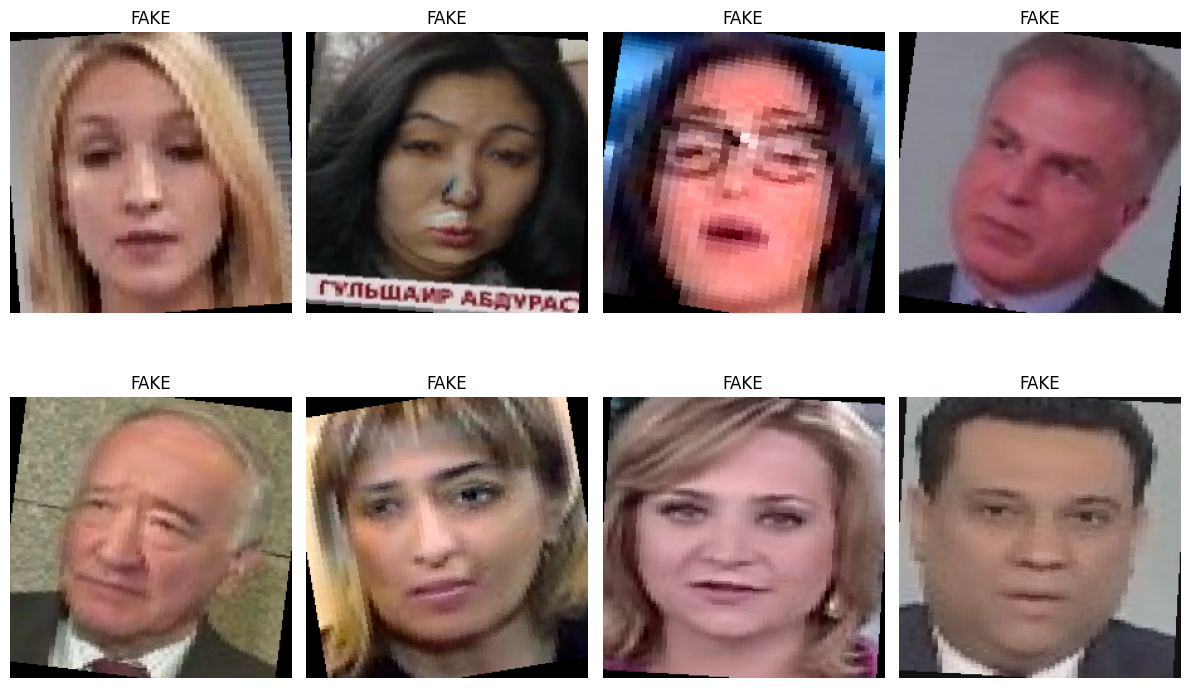

In [ ]:
# Lấy một batch từ TRAIN
images, labels = next(
    iter(train_loader)
)


# Chuyển tensor về dạng hiển thị
mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(1, 3, 1, 1)


display_images = (
    images.cpu() * std + mean
)

display_images = torch.clamp(
    display_images,
    0,
    1
)


plt.figure(
    figsize=(12, 8)
)

for i in range(8):

    plt.subplot(
        2,
        4,
        i + 1
    )

    img = (
        display_images[i]
        .permute(1, 2, 0)
        .numpy()
    )

    plt.imshow(img)

    label = labels[i].item()

    plt.title(
        LABEL_TO_CLASS[label]
    )

    plt.axis("off")


plt.tight_layout()
plt.show()

In [ ]:
def create_model(
    model_name
):

    if model_name == "resnet50":

        model = resnet50(
            weights=ResNet50_Weights.DEFAULT
        )

        in_features = (
            model.fc.in_features
        )

        model.fc = nn.Linear(
            in_features,
            2
        )


    elif model_name == "efficientnet_b0":

        model = efficientnet_b0(
            weights=EfficientNet_B0_Weights.DEFAULT
        )

        in_features = (
            model.classifier[-1]
            .in_features
        )

        model.classifier[-1] = nn.Linear(
            in_features,
            2
        )


    elif model_name == "convnext_tiny":

        model = convnext_tiny(
            weights=ConvNeXt_Tiny_Weights.DEFAULT
        )

        in_features = (
            model.classifier[-1]
            .in_features
        )

        model.classifier[-1] = nn.Linear(
            in_features,
            2
        )


    else:

        raise ValueError(
            f"Unknown model: "
            f"{model_name}"
        )


    return model

In [ ]:
MODEL_NAMES = [
    "resnet50",
    "efficientnet_b0",
    "convnext_tiny"
]


for model_name in MODEL_NAMES:

    model = create_model(
        model_name
    )

    total_params = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    print(
        f"{model_name:20s}"
        f" | Params: "
        f"{total_params / 1e6:.2f}M"
    )

    del model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

resnet50             | Params: 23.51M
efficientnet_b0      | Params: 4.01M
convnext_tiny        | Params: 27.82M


In [ ]:
class_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
)


print("Class counts:")

for label, count in class_counts.items():

    print(
        LABEL_TO_CLASS[label],
        ":",
        f"{count:,}"
    )


total_samples = len(
    train_df
)

num_classes = 2


class_weights = []

for label in range(num_classes):

    count = class_counts[
        label
    ]

    weight = (
        total_samples
        / (num_classes * count)
    )

    class_weights.append(
        weight
    )


class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)


print("\nClass weights:")

for label, weight in enumerate(
    class_weights
):

    print(
        LABEL_TO_CLASS[label],
        ":",
        f"{weight.item():.4f}"
    )

Class counts:
REAL : 7,898
FAKE : 46,448

Class weights:
REAL : 3.4405
FAKE : 0.5850


In [ ]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

print(criterion)

CrossEntropyLoss()


In [ ]:
def create_optimizer(
    model
):

    return torch.optim.AdamW(
        model.parameters(),

        lr=LEARNING_RATE,

        weight_decay=WEIGHT_DECAY
    )

In [ ]:
def create_scheduler(
    optimizer
):

    return torch.optim.lr_scheduler.ReduceLROnPlateau(

        optimizer,

        mode="max",

        factor=0.5,

        patience=1,

        min_lr=1e-6
    )

In [ ]:
def train_one_epoch(
    model,
    train_loader,
    criterion,
    optimizer,
    scaler
):

    model.train()

    running_loss = 0.0

    all_preds = []
    all_labels = []


    progress = tqdm(
        loader,
        desc="Train",
        leave=False
    )


    for images, labels in progress:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        # channels_last tối ưu CNN trên CUDA
        if device.type == "cuda":

            images = images.contiguous(
                memory_format=torch.channels_last
            )


        optimizer.zero_grad(
            set_to_none=True
        )


        # Mixed Precision
        with torch.amp.autocast(
            device_type=device.type,
            enabled=USE_AMP
        ):

            outputs = model(
                images
            )

            loss = criterion(
                outputs,
                labels
            )


        if USE_AMP:

            scaler.scale(
                loss
            ).backward()

            scaler.step(
                optimizer
            )

            scaler.update()

        else:

            loss.backward()

            optimizer.step()


        running_loss += (
            loss.item()
            * images.size(0)
        )


        preds = torch.argmax(
            outputs,
            dim=1
        )


        all_preds.extend(
            preds.detach()
            .cpu()
            .numpy()
        )

        all_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
        )


    epoch_loss = (
        running_loss
        / len(loader.dataset)
    )


    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        pos_label=1,
        zero_division=0
    )


    return epoch_loss, epoch_f1

In [ ]:
def validate(
    model,
    loader,
    criterion
):

    model.eval()

    running_loss = 0.0

    all_preds = []
    all_labels = []
    all_probs = []


    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )


            if device.type == "cuda":

                images = images.contiguous(
                    memory_format=torch.channels_last
                )


            with torch.amp.autocast(
                device_type=device.type,
                enabled=USE_AMP
            ):

                outputs = model(
                    images
                )

                loss = criterion(
                    outputs,
                    labels
                )


            running_loss += (
                loss.item()
                * images.size(0)
            )


            probabilities = torch.softmax(
                outputs,
                dim=1
            )


            preds = torch.argmax(
                outputs,
                dim=1
            )


            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_probs.extend(
                probabilities[:, 1]
                .cpu()
                .numpy()
            )


    epoch_loss = (
        running_loss
        / len(loader.dataset)
    )


    accuracy = accuracy_score(
        all_labels,
        all_preds
    )


    precision = precision_score(
        all_labels,
        all_preds,
        pos_label=1,
        zero_division=0
    )


    recall = recall_score(
        all_labels,
        all_preds,
        pos_label=1,
        zero_division=0
    )


    f1 = f1_score(
        all_labels,
        all_preds,
        pos_label=1,
        zero_division=0
    )


    auc = roc_auc_score(
        all_labels,
        all_probs
    )


    return {
        "loss": epoch_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": auc
    }

In [ ]:
def save_checkpoint(
    model,
    optimizer,
    scheduler,
    scaler,
    epoch,
    metrics,
    model_name,
    best_f1
):

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"{model_name}_best.pth"
    )


    checkpoint = {

        "model_name":
            model_name,

        "epoch":
            epoch,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "scheduler_state_dict":
            scheduler.state_dict(),

        "scaler_state_dict":
            scaler.state_dict()
            if USE_AMP
            else None,

        "best_f1":
            best_f1,

        "metrics":
            metrics,

        "config": {

            "img_size":
                IMG_SIZE,

            "batch_size":
                BATCH_SIZE,

            "epochs":
                EPOCHS,

            "learning_rate":
                LEARNING_RATE,

            "weight_decay":
                WEIGHT_DECAY,

            "seed":
                SEED

        }
    }


    torch.save(
        checkpoint,
        checkpoint_path
    )


    return checkpoint_path

In [ ]:
def finetune_convnext(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    epochs,
    experiment_name
):

    history = []

    best_f1 = -1.0
    best_auc = -1.0
    best_epoch = -1

    experiment_checkpoint = os.path.join(
        CHECKPOINT_DIR,
        f"{experiment_name}_best.pth"
    )

    total_start = time.time()

    for epoch in range(epochs):

        epoch_start = time.time()

        print("\n" + "=" * 70)
        print(
            f"{experiment_name} | "
            f"Epoch {epoch + 1}/{epochs}"
        )
        print("=" * 70)

        # TRAIN
        train_loss, train_f1 = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            torch.amp.GradScaler(
                "cuda",
                enabled=USE_AMP
            )
        )

        # VALIDATION
        val_metrics = validate(
            model,
            val_loader,
            criterion
        )

        # Scheduler
        scheduler.step(
            val_metrics["f1"]
        )

        epoch_time = (
            time.time() - epoch_start
        )

        current_lr = (
            optimizer.param_groups[0]["lr"]
        )

        row = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_f1": train_f1,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_precision": val_metrics["precision"],
            "val_recall": val_metrics["recall"],
            "val_f1": val_metrics["f1"],
            "val_roc_auc": val_metrics["roc_auc"],
            "learning_rate": current_lr,
            "epoch_time_sec": epoch_time
        }

        history.append(row)

        print(
            f"Train Loss : {train_loss:.4f}"
        )
        print(
            f"Train F1   : {train_f1:.4f}"
        )
        print(
            f"Val F1     : {val_metrics['f1']:.4f}"
        )
        print(
            f"Val AUC    : {val_metrics['roc_auc']:.4f}"
        )
        print(
            f"LR         : {current_lr:.2e}"
        )

        # BEST
        is_better = (
            val_metrics["f1"] > best_f1
            or
            (
                val_metrics["f1"] == best_f1
                and
                val_metrics["roc_auc"] > best_auc
            )
        )

        if is_better:

            best_f1 = val_metrics["f1"]
            best_auc = val_metrics["roc_auc"]
            best_epoch = epoch + 1

            torch.save(
                {
                    "experiment":
                        experiment_name,

                    "model_name":
                        "convnext_tiny",

                    "epoch":
                        epoch + 1,

                    "model_state_dict":
                        model.state_dict(),

                    "optimizer_state_dict":
                        optimizer.state_dict(),

                    "scheduler_state_dict":
                        scheduler.state_dict(),

                    "best_f1":
                        best_f1,

                    "best_auc":
                        best_auc,

                    "metrics":
                        val_metrics
                },
                experiment_checkpoint
            )

            print(
                "✓ BEST CHECKPOINT SAVED"
            )

    history_df = pd.DataFrame(
        history
    )

    history_path = os.path.join(
        HISTORY_DIR,
        f"{experiment_name}_history.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    total_time = (
        time.time() - total_start
    )

    summary = {
        "experiment":
            experiment_name,

        "best_epoch":
            best_epoch,

        "best_val_f1":
            best_f1,

        "best_val_roc_auc":
            best_auc,

        "checkpoint":
            experiment_checkpoint,

        "history":
            history_path,

        "total_time_sec":
            total_time
    }

    return summary, history_df

    # =========================
    # Free GPU
    # =========================

    del model
    del optimizer
    del scheduler
    del scaler

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return summary, history_df